# Stage 1 — Data audit and exploratory data analysis (EDA)

**Input:** `data/processed/power_parsed.parquet` (from Stage 0: raw values, `-999 → NaN` only).
**Rule for this stage:** we *look*, we do **not** clean or transform the stored data. Where a plot needs to ignore invalid
values (e.g. the corrupted WD2M), we mask them *inside the calculation only* and say so.

**Targets (decided after Stage 0, see DECISIONS.md):** primary `PRECTOTCORR` (1981–2025), secondary `IMERG_PRECTOT`
(1998–2025). Split protocol: train 1981–2019 (validation folds inside it, 2014–2019), **test 2020–2025 (locked)**.

### Which years does each analysis use? (important — rule 4)
EDA that can influence **modelling choices** (distributions, thresholds, climatology, spells, autocorrelation,
predictor–target correlations) uses **training years only (1981–2019)**. If we looked at test-period correlations to pick
features, the test set would no longer be an honest, unseen evaluation ("data snooping").

**Data-integrity checks** (missingness, impossible values, annual totals, homogeneity, last-12-months comparison) use the
**full record**, because their purpose is to detect broken or shifted *data*, not to tune models. They do not use any model
output on the test period. We state this distinction in the paper.

### Step 1 — Setup and load

**WHAT:** imports, constants (target names, training end date, season definition), a figure-saving helper, and load the
parquet file.

**WHY:** one place for all settings makes the notebook easy to audit. Seasons follow the standard Bangladesh convention:
pre-monsoon (Mar–May), monsoon (Jun–Sep), post-monsoon (Oct–Nov), winter (Dec–Feb).

**Alternatives considered:** the 3-month meteorological seasons (DJF, MAM, JJA, SON) — common in mid-latitude studies, but
they split the South-Asian monsoon (Jun–Sep) in two, so the Bangladesh convention is more meaningful here.

**Look for:** the file loads with 16,436 rows and a `DatetimeIndex`.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy, statsmodels
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

SEED = 42; np.random.seed(SEED)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, TAB = ROOT / "reports/figures", ROOT / "reports/tables"
TARGET, ALT = "PRECTOTCORR", "IMERG_PRECTOT"
TRAIN_END, TEST_START = "2019-12-31", "2020-01-01"
THRESHOLDS = [0.1, 1.0, 2.5]
SEASON = {12: "winter", 1: "winter", 2: "winter", 3: "pre-monsoon", 4: "pre-monsoon", 5: "pre-monsoon",
          6: "monsoon", 7: "monsoon", 8: "monsoon", 9: "monsoon", 10: "post-monsoon", 11: "post-monsoon"}
SEASONS = ["pre-monsoon", "monsoon", "post-monsoon", "winter"]
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)

def save(fig, name):
    fig.savefig(FIG / name, dpi=300, bbox_inches="tight")

df = pd.read_parquet(ROOT / "data/processed/power_parsed.parquet")
VARS = [c for c in df.columns if c not in ("YEAR", "DOY")]
train = df.loc[:TRAIN_END]
print("pandas", pd.__version__, "| scipy", scipy.__version__, "| statsmodels", statsmodels.__version__)
print("full:", df.shape, df.index.min().date(), "->", df.index.max().date(), "| train:", train.shape)

pandas 3.0.5 | scipy 1.18.1 | statsmodels 0.15.0
full: (16436, 15) 1981-01-01 -> 2025-12-31 | train: (14244, 15)


**Interpretation:** the processed file loads: 16,436 days (1981-01-01 → 2025-12-31); the training period 1981–2019 has
14,244 days. Library versions are printed for the record.

**Decision:** all modelling-relevant EDA below uses `train` (1981–2019); integrity checks use `df` (full record).

**Paper note:** *Exploratory analyses informing model design were restricted to the training period (1981–2019); the
2020–2025 test period was used only for data-integrity checks and was otherwise withheld until final evaluation.*

## Section 1 — Structure, duplicates and missingness

### Step 2 — Shape, dtypes, duplicates, regular daily frequency

**WHAT:** re-check the basic structure of the processed file.

**WHY:** Stage 0 checked the *raw* file. Each notebook must stand on its own (rule 15), so we confirm that what we read
from disk is what we expect — a broken save or a wrong file would show up here.

**Alternatives considered:** trusting Stage 0 — faster, but then a silent change to the parquet file would go unnoticed.

**Look for:** 16,436 × 15, numeric dtypes, 0 duplicated dates, inferred frequency `D`, 0 fully duplicated rows.

In [2]:
print("shape:", df.shape)
print("dtypes:", df.dtypes.value_counts().to_dict())
print("duplicated dates:", df.index.duplicated().sum(), "| duplicated rows:", df.duplicated().sum())
print("inferred frequency:", pd.infer_freq(df.index))

shape: (16436, 15)
dtypes: {dtype('float64'): 13, dtype('int64'): 2}
duplicated dates: 0 | duplicated rows: 0
inferred frequency: D


**Interpretation:** identical to Stage 0: 16,436 × 15, all numeric, no duplicated dates or rows, and pandas infers a
regular daily frequency (`D`). The processed file is a faithful copy of the parsed raw data.

**Decision:** no structural fixes needed.

**Paper note:** *The processed series formed a regular daily time series without duplicated or missing time stamps.*

### Step 3 — Missingness by variable and by year (including invalid WD2M)

**WHAT:** for each variable and year, compute the fraction of days that are **unusable**: NaN (`-999` in the raw file)
*or* physically invalid. For WD2M "invalid" means outside 0–360°.

**WHY:** a model can only use a variable where it exists. The *pattern* over years tells us which variables can enter
which feature set and which period they support. Counting invalid WD2M as unusable makes the problem visible in the same
table as ordinary missingness.

**Alternatives considered:** counting only NaN — would report WD2M as 100 % complete, which is misleading.

**Look for:** the block structure (IMERG before 1998, radiation before 1984, WD2M from 2013 on).

WD2M invalid from 2012-12-31 to 2025-12-31


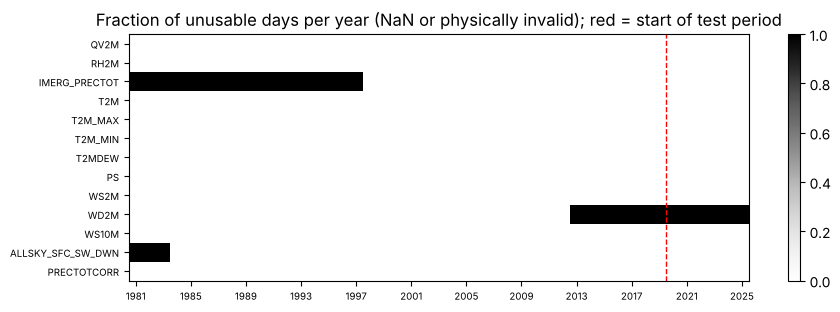

,n_NaN,n_invalid,pct_unusable
QV2M,0,0,0.0
RH2M,0,0,0.0
IMERG_PRECTOT,6209,0,37.8
T2M,0,0,0.0
T2M_MAX,0,0,0.0
T2M_MIN,0,0,0.0
T2MDEW,0,0,0.0
PS,0,0,0.0
WS2M,0,0,0.0
WD2M,0,4749,28.9


In [3]:
wd_invalid = (df["WD2M"] < 0) | (df["WD2M"] > 360)
unusable = df[VARS].isna()
unusable["WD2M"] = wd_invalid
by_var = pd.DataFrame({"n_NaN": df[VARS].isna().sum(), "n_invalid": 0, "pct_unusable": (unusable.mean() * 100).round(1)})
by_var.loc["WD2M", "n_invalid"] = wd_invalid.sum()
by_year = unusable.groupby(df.index.year).mean()
by_var.to_csv(TAB / "01_unusable_by_variable.csv"); by_year.round(3).to_csv(TAB / "01_unusable_by_year.csv")
print("WD2M invalid from", df.index[wd_invalid].min().date(), "to", df.index[wd_invalid].max().date())

fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(by_year.T, aspect="auto", cmap="Greys", vmin=0, vmax=1)
ax.set_yticks(range(len(VARS)), VARS, fontsize=7); ax.set_xticks(range(0, 45, 4), by_year.index[::4], fontsize=7)
ax.axvline(2019.5 - 1981, color="red", ls="--", lw=1)
ax.set_title("Fraction of unusable days per year (NaN or physically invalid); red = start of test period")
fig.colorbar(im, ax=ax); save(fig, "01_unusable_by_year.png"); plt.show()
by_var

**Interpretation:** three variables are unusable for part of the record, each as a **contiguous block**:
- `IMERG_PRECTOT` 37.8 % (1981–1997, product not yet available),
- `WD2M` 28.9 % (**invalid from 2012-12-31 to 2025-12-31** — it covers the last training years, all validation years and
  the whole test period),
- `ALLSKY_SFC_SW_DWN` 6.7 % (1981–1983).
All other variables (including the primary target `PRECTOTCORR`) are 100 % complete.

**Decision:** confirms your Stage-0 decision: WD2M is flagged now and dropped in Stage 2. Radiation and IMERG cannot be
used in a model that trains from 1981 without either shortening the period or imputing whole years (not acceptable).

**Paper note:** *Data gaps were structural rather than random: IMERG precipitation was unavailable before 1998, surface
shortwave radiation before 1984, and 2-m wind direction contained invalid values throughout 2013–2025.*

## Section 2 — Summary statistics and physically impossible values

### Step 4 — Summary statistics per variable (training period) and impossible-value flags (full record)

**WHAT:** `describe()` plus skewness for each variable over 1981–2019, and a count of physically impossible values over
the whole record.

**WHY:** summary statistics tell us scale (relevant for scaling and regularisation later), skewness tells us which
variables are far from symmetric (rainfall), and impossible values must be known before any modelling.

**Alternatives considered:** robust statistics (median/IQR) only — we include the quartiles in `describe()`, so we get both.

**Look for:** extreme skewness of the rainfall variables, the absurd WD2M statistics, and zero impossible values elsewhere.

In [4]:
summ = train[VARS].describe().T
summ["skew"] = train[VARS].skew()
BOUNDS = {"QV2M": (0, 30), "RH2M": (0, 100), "IMERG_PRECTOT": (0, 500), "T2M": (-5, 45), "T2M_MAX": (-5, 50),
          "T2M_MIN": (-10, 40), "T2MDEW": (-15, 35), "PS": (95, 105), "WS2M": (0, 30), "WD2M": (0, 360),
          "WS10M": (0, 40), "ALLSKY_SFC_SW_DWN": (0, 35), "PRECTOTCORR": (0, 500)}
summ["n_impossible_full_record"] = [((df[c] < lo) | (df[c] > hi)).sum() for c, (lo, hi) in BOUNDS.items()]
summ.round(2).to_csv(TAB / "01_summary_stats_train.csv")
summ.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,n_impossible_full_record
QV2M,14244.0,14.95,5.35,3.07,9.80,15.69,20.12,24.18,-0.26,0
RH2M,14244.0,74.13,14.97,17.84,66.08,77.68,85.90,96.87,-1.00,0
IMERG_PRECTOT,8035.0,10.13,20.27,0.00,0.00,0.57,11.74,229.39,3.69,0
T2M,14244.0,24.61,4.24,10.90,21.06,26.29,27.89,33.64,-0.66,0
T2M_MAX,14244.0,29.40,3.60,17.13,27.02,30.01,31.74,41.50,-0.29,0
T2M_MIN,14244.0,20.24,5.28,4.22,15.42,22.24,24.85,28.76,-0.58,0
T2MDEW,14244.0,19.09,6.50,-3.03,13.62,20.99,25.00,27.99,-0.66,0
PS,14244.0,99.62,0.54,97.88,99.19,99.64,100.07,100.92,-0.13,0
WS2M,14244.0,1.52,0.53,0.58,1.19,1.37,1.67,6.75,2.11,0
WD2M,14244.0,-1155.78,2856.72,-8998.00,30.20,156.10,219.70,360.00,-1.73,4749


**Interpretation:**
- **Rainfall is extremely skewed** (skew ≈ 4.0 for PRECTOTCORR, 3.7 for IMERG): median 0.9 mm but mean 7.7 mm and max
  288 mm. Squared-error losses will be dominated by a few large days → consider log1p-transformed regression targets or
  robust metrics (MAE) alongside RMSE.
- Variable scales differ by orders of magnitude (PS ≈ 99.6 with std 0.54; rainfall std 14.9) → linear models, SGD and the
  MLP need standardisation (fitted on training data only, inside a Pipeline — rule 6).
- **Physically impossible values: only WD2M (4,749).** Note how its training-period mean (−1,156°) and std (2,857°) are
  pure artefacts — a reminder that summary statistics silently absorb broken data.
- Wind speeds are right-skewed (≈ 2); temperatures and humidity mildly left-skewed (seasonal: long dry season tail).

**Decision:** no data change now. Note for Stage 3: scaling for linear/NN models; consider `log1p` target for regression.

**Paper note:** *Daily precipitation was strongly right-skewed (skewness ≈ 4), whereas the thermodynamic predictors were
approximately symmetric; no physically impossible values were found apart from the invalid wind-direction record.*

## Section 3 — Rainfall distribution

### Step 5 — Histograms on linear and log scale (training period)

**WHAT:** histograms of daily `PRECTOTCORR` and `IMERG_PRECTOT` on a linear axis, and of wet-day amounts on a log axis.

**WHY:** the shape of the target decides the loss function and metric. Daily rainfall is typically **zero-inflated**
(many exact zeros) and **heavy-tailed** (rare huge values). The linear plot shows the spike at zero; the log-x plot of
wet days shows the shape of the non-zero part.

**Alternatives considered:** a kernel density plot — smooths over the zero spike and hides exactly what we need to see.

**Look for:** the height of the spike at 0, how far the tail reaches, and whether the two products look alike.
For a fair comparison both products are shown over their common training years (1998–2019).

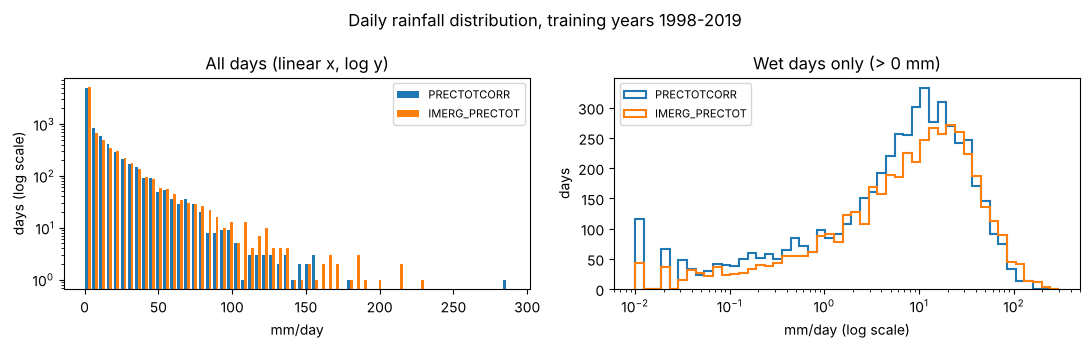

In [5]:
common = train.loc["1998":, [TARGET, ALT]]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist([common[TARGET], common[ALT]], bins=60, label=[TARGET, ALT])
axes[0].set(yscale="log", xlabel="mm/day", ylabel="days (log scale)", title="All days (linear x, log y)")
bins = np.logspace(-2, np.log10(300), 50)
for c in (TARGET, ALT):
    axes[1].hist(common[c][common[c] > 0], bins=bins, histtype="step", lw=1.5, label=c)
axes[1].set(xscale="log", xlabel="mm/day (log scale)", ylabel="days", title="Wet days only (> 0 mm)")
for a in axes: a.legend(fontsize=8)
fig.suptitle("Daily rainfall distribution, training years 1998-2019"); fig.tight_layout(); save(fig, "01_rain_histograms.png"); plt.show()

**Interpretation:** both products show the classic **zero-inflated, heavy-tailed** shape: a huge spike at 0, then an
approximately exponential decay (straight-ish line on the log-y axis). On the log-x plot, wet-day amounts peak around
10–20 mm/day. Differences: PRECTOTCORR has **more very small values (0.01–0.03 mm, "model drizzle")** and more moderate
5–15 mm days, while IMERG has more exact zeros and a slightly longer upper tail (more days > 150 mm in 1998–2019).

**Decision:** the drizzle peak in PRECTOTCORR means the 0.1 mm threshold mostly measures model drizzle, not meaningful rain
— this supports ≥ 1 mm as the primary threshold. For regression, a single Gaussian-error model is a poor fit for such data;
we will compare MSE-based models on raw and log1p targets, and possibly Tweedie loss (natively supported by LightGBM/XGBoost
— to be verified for the installed versions in Stage 3).

**Paper note:** *Daily rainfall exhibited a zero-inflated, heavy-tailed distribution, with the reanalysis product showing a
higher frequency of trace amounts (< 0.1 mm) than the satellite product.*

### Step 6 — Share of zero days and of days below 0.1, 1 and 2.5 mm

**WHAT:** the fraction of days that are exactly 0 and below each threshold, for both products, over the full training
period (PRECTOTCORR 1981–2019) and the common period (1998–2019).

**WHY:** these shares are the **class balance** of our classification task (rain = ≥ threshold). They also tell us how
"drizzle" is handled: reanalysis models often produce many tiny non-zero values, satellites produce more exact zeros.

**Alternatives considered:** only reporting the ≥ 1 mm share — but we promised 0.1 and 2.5 mm as sensitivity thresholds,
and the difference between them shows how much drizzle each product contains.

**Look for:** how balanced the ≥ 1 mm classes are; the gap between "= 0" and "< 0.1 mm".

In [6]:
def shares(s):
    s = s.dropna()
    return pd.Series({"n_days": len(s), "= 0": (s == 0).mean(), **{f"< {t}": (s < t).mean() for t in THRESHOLDS}})

share_tab = pd.DataFrame({f"{TARGET} 1981-2019": shares(train[TARGET]),
                          f"{TARGET} 1998-2019": shares(common[TARGET]),
                          f"{ALT} 1998-2019": shares(common[ALT])}).T
share_tab.round(3).to_csv(TAB / "01_rain_threshold_shares.csv")
share_tab.round(3)

,n_days,= 0,< 0.1,< 1.0,< 2.5
PRECTOTCORR 1981-2019,14244.0,0.352,0.406,0.506,0.578
PRECTOTCORR 1998-2019,8035.0,0.347,0.394,0.480,0.537
IMERG_PRECTOT 1998-2019,8035.0,0.429,0.458,0.522,0.579


**Interpretation:**
- PRECTOTCORR 1981–2019: 35.2 % exact zeros; 40.6 % below 0.1 mm; **50.6 % below 1 mm** → the ≥ 1 mm classification task is
  almost perfectly balanced over the year (49.4 % rain days); 57.8 % below 2.5 mm.
- Over the common years 1998–2019, PRECTOTCORR has fewer zeros than IMERG (34.7 % vs 42.9 %) but the shares converge at
  higher thresholds (< 2.5 mm: 53.7 % vs 57.9 %). The products agree better on "real" rain than on drizzle.

**Decision:** keep ≥ 1 mm as primary threshold (balanced overall; robust to drizzle differences). Because the balance is
near 50/50 overall but very unequal by season (Step 10), we will report ROC-AUC, Brier score, F1 and balanced metrics, not
accuracy alone.

**Paper note:** *Over the training period, 49.4 % of days recorded at least 1 mm of rainfall (PRECTOTCORR), yielding an
approximately balanced binary classification problem at the annual scale.*

### Step 7 — Top 20 extreme rainfall days (training period)

**WHAT:** the 20 wettest `PRECTOTCORR` days in 1981–2019, with the IMERG value on the same day.

**WHY:** extremes dominate RMSE (errors are squared), so we must know whether they are real events or artefacts.
Checking whether IMERG also shows heavy rain on the same date is a simple plausibility test. Their **years** also reveal
inhomogeneity: if all extremes cluster in recent years, the product has changed, not necessarily the climate.

**Alternatives considered:** annual maxima per year — better for extreme-value statistics; the top-20 list is simpler and
answers our question ("are the biggest values believable, and when do they occur?").

**Look for:** the years of the extremes, the months (monsoon expected), and agreement with IMERG.

In [7]:
top = train[[TARGET, ALT]].nlargest(20, TARGET)
top.insert(0, "month", top.index.month)
top.to_csv(TAB / "01_top20_extreme_days_train.csv")
print("years of top-20:", top.index.year.value_counts().sort_index().to_dict())
top

years of top-20: {1982: 1, 2004: 1, 2007: 1, 2010: 1, 2014: 1, 2015: 1, 2016: 1, 2017: 7, 2019: 6}


,month,PRECTOTCORR,IMERG_PRECTOT
date,,,
2017-06-16,6,288.10,40.83
2017-08-11,8,177.96,88.66
2017-06-12,6,156.73,46.58
2019-07-09,7,156.40,20.45
2019-07-10,7,155.10,73.91
2015-06-10,6,153.38,117.83
2019-05-04,5,152.03,33.36
2017-08-12,8,148.10,68.60
2017-10-21,10,147.67,107.13


**Interpretation (a red flag):**
- **13 of the 20 wettest days are in 2017 (7) and 2019 (6)**, and 15 of 20 are in 2015–2019. Only one day is before 2004.
  A real climate signal would not concentrate extremes this strongly in a 5-year window after decades without them.
- On those days IMERG often reports much less: the record 288 mm (2017-06-16) is 41 mm in IMERG; 2019-07-09 is 156 vs 20 mm;
  2017-06-02 is 138 vs 16 mm. In older years the agreement is much closer (e.g. 2004-07-19: 126 vs 149 mm; 2010-10-08:
  136 vs 100 mm).
- All extremes fall in May–October (monsoon and its margins), which is physically sensible.

**Decision:** we do **not** remove or cap these values (they are the target and we have no proof they are wrong for
MERRA-2), but they are evidence that the post-2016 PRECTOTCORR regime is different. Rule 11 applies in reverse here:
very large *errors* on 2016+ extremes in validation should first be checked against this.

**Paper note:** *The largest PRECTOTCORR daily totals were concentrated in 2015–2019 and were frequently not corroborated
by IMERG on the same dates, consistent with a change in the reanalysis precipitation correction rather than a change in
the underlying climate.*

### Step 8 — Annual totals: PRECTOTCORR vs IMERG (full record, integrity check)

**WHAT:** annual rainfall totals of both products, 1981–2025, and the ratio PRECTOTCORR / IMERG where both exist.

**WHY:** the ratio is a powerful homogeneity diagnostic: weather variability affects both products similarly, so a
*sudden* change in their ratio points to a change in one product's processing. Uses the full record because it is a data
check, not a modelling choice.

**Alternatives considered:** comparing against BMD station data for Sylhet — the gold standard, which we don't have in the
repository; worth adding for the paper if you can obtain it.

**Look for:** level of each series, and whether the ratio is stable or jumps.

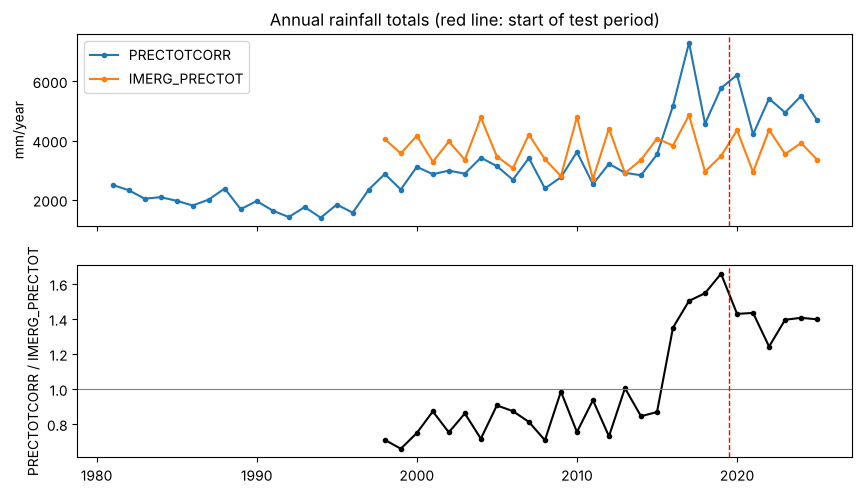

           mean   std
1998-2015  0.82  0.10
2016-2025  1.44  0.11


In [8]:
annual = df.groupby(df.index.year)[[TARGET, ALT]].sum(min_count=360)
annual["ratio"] = annual[TARGET] / annual[ALT]
annual.round(2).to_csv(TAB / "01_annual_totals.csv")

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
annual[[TARGET, ALT]].plot(ax=axes[0], marker="o", ms=3); axes[0].set_ylabel("mm/year")
axes[1].plot(annual.index, annual["ratio"], "o-", ms=3, color="k"); axes[1].axhline(1, color="grey", lw=0.8)
axes[1].set_ylabel(f"{TARGET} / {ALT}")
for a in axes: a.axvline(2019.5, color="red", ls="--", lw=1)
axes[0].set_title("Annual rainfall totals (red line: start of test period)")
save(fig, "01_annual_totals_and_ratio.png"); plt.show()
print(annual.loc[1998:, "ratio"].groupby(annual.loc[1998:].index >= 2016).agg(["mean", "std"])
      .rename(index={False: "1998-2015", True: "2016-2025"}).round(2))

**Interpretation:** the ratio PRECTOTCORR / IMERG is **0.82 ± 0.10 in 1998–2015 and 1.44 ± 0.11 in 2016–2025** — a jump of
~75 % from one year to the next, with very little year-to-year scatter on either side. A step this clean in a ratio of
two independent products is the signature of a **processing change in one product** (here PRECTOTCORR, because IMERG stays
level; see Steps 15–16). Note also that the jump sits **inside** our training/validation period (2016–2019), and the whole
test period (2020–2025) lies in the new regime.

**Decision:** no correction of the target (adjusting a target to look homogeneous would fabricate data). Instead: (i) the
IMERG robustness analysis you decided on becomes essential, and (ii) I propose a training-window ablation (e.g. 1981–2019
vs 2000–2019 vs 2016–2019) and reporting validation scores separately for 2014–2015 and 2016–2019 (Stage 2 plan below).

**Paper note:** *The ratio of annual PRECTOTCORR to IMERG totals shifted abruptly from 0.82 ± 0.10 (1998–2015) to
1.44 ± 0.11 (2016–2025), indicating a discontinuity in the MERRA-2 corrected precipitation at the study grid cell.*

## Section 4 — Seasonality

### Step 9 — Monthly climatology of all variables (training period)

**WHAT:** mean and standard deviation of each variable for each calendar month, 1981–2019.

**WHY:** Sylhet's weather is dominated by the monsoon cycle. Knowing the seasonal cycle (i) defines our climatology
baseline, (ii) tells us that much of any variable–rain correlation will simply be "both follow the season", and
(iii) suggests seasonal features (month, day-of-year sine/cosine).

**Alternatives considered:** day-of-year climatology (366 values) — smoother seasonality, used later for the baseline;
monthly is easier to read here. **WD2M is excluded**: a mean of wind *directions* is not meaningful (the mean of 350° and
10° is 180°, which points the wrong way), and its post-2012 values are invalid; circular statistics would be needed.

**Look for:** the timing of the rainy season, and which variables move with it (humidity, pressure, temperature).

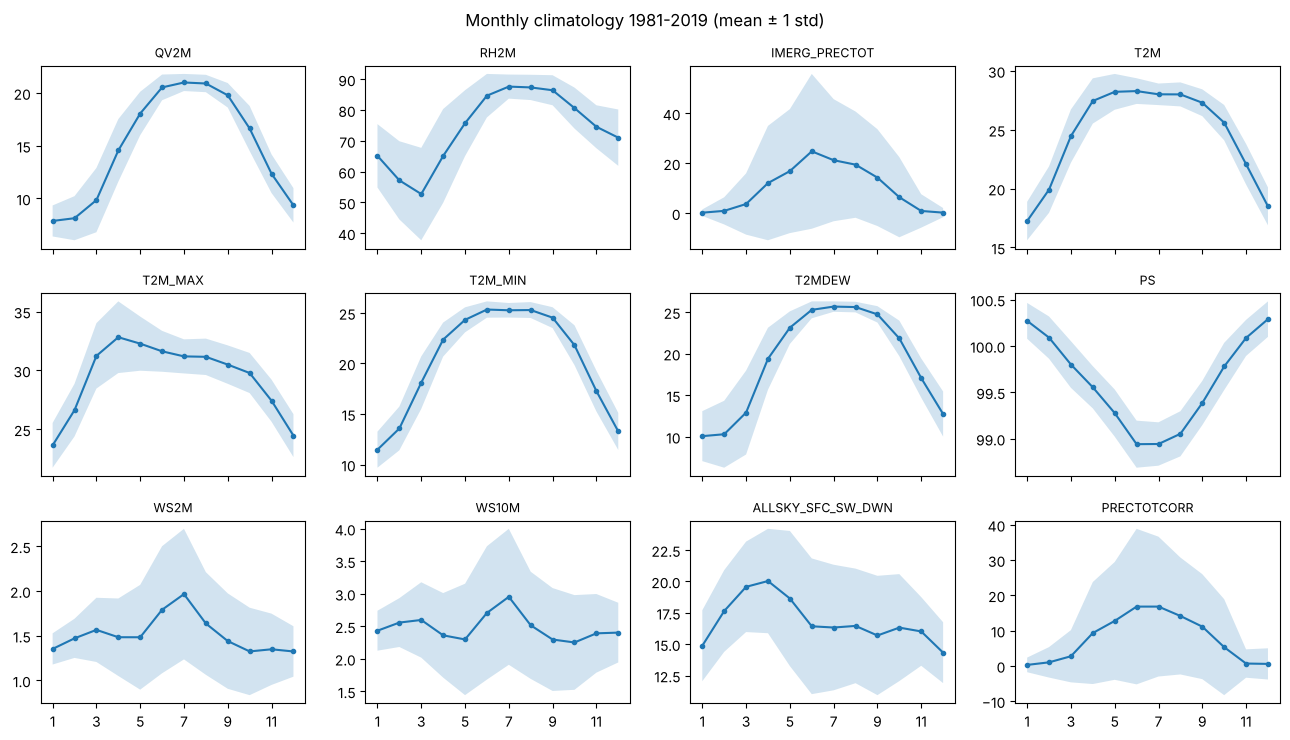

,QV2M,RH2M,IMERG_PRECTOT,T2M,T2M_MAX,T2M_MIN,T2MDEW,PS,WS2M,WS10M,ALLSKY_SFC_SW_DWN,PRECTOTCORR
date,,,,,,,,,,,,
1,7.87,65.16,0.21,17.25,23.64,11.47,10.07,100.27,1.35,2.43,14.87,0.27
2,8.13,57.20,0.94,19.92,26.63,13.57,10.30,100.09,1.47,2.56,17.64,1.00
3,9.84,52.74,3.69,24.46,31.23,18.10,12.91,99.80,1.57,2.60,19.57,2.73
4,14.55,65.12,12.07,27.45,32.82,22.36,19.38,99.55,1.48,2.36,20.03,9.31
5,18.05,75.76,16.86,28.22,32.27,24.31,23.12,99.28,1.48,2.30,18.64,12.75
6,20.53,84.70,24.78,28.29,31.62,25.33,25.27,98.94,1.79,2.70,16.42,16.81
7,21.00,87.65,21.24,28.01,31.19,25.26,25.66,98.94,1.97,2.95,16.32,16.81
8,20.90,87.38,19.45,28.01,31.15,25.28,25.60,99.05,1.64,2.51,16.45,14.14
9,19.78,86.46,14.26,27.30,30.49,24.53,24.73,99.38,1.44,2.30,15.69,11.12


In [9]:
CLIM_VARS = [v for v in VARS if v != "WD2M"]
clim = train[CLIM_VARS].groupby(train.index.month).agg(["mean", "std"])
clim.round(2).to_csv(TAB / "01_monthly_climatology_train.csv")

fig, axes = plt.subplots(3, 4, figsize=(13, 7.5), sharex=True)
for ax, v in zip(axes.flat, CLIM_VARS):
    m, s = clim[(v, "mean")], clim[(v, "std")]
    ax.plot(m.index, m, "o-", ms=3); ax.fill_between(m.index, m - s, m + s, alpha=0.2)
    ax.set_title(v, fontsize=9); ax.set_xticks(range(1, 13, 2))
fig.suptitle("Monthly climatology 1981-2019 (mean ± 1 std)"); fig.tight_layout()
save(fig, "01_monthly_climatology.png"); plt.show()
clim.xs("mean", axis=1, level=1).round(2)

**Interpretation:** a textbook **monsoon climate**:
- Rainfall rises from < 1 mm/day (Nov–Feb) to ~17 mm/day in Jun–Jul (PRECTOTCORR; IMERG peaks at ~25 mm/day in June).
  April–May are already wet (pre-monsoon thunderstorms, "nor'westers", typical for Sylhet).
- Humidity (QV2M 8 → 21 g/kg, RH2M 53 → 88 %), dew point and minimum temperature follow the same cycle; surface pressure
  is its mirror image (100.3 kPa in winter → 98.9 kPa in Jun–Jul, the monsoon trough).
- Radiation peaks in **April** (~20 MJ m⁻²) and *drops* during the monsoon because of cloud cover, despite the higher sun.
- Wind speed peaks in July (monsoon flow), but the seasonal range is small.

**Decision:** include seasonal features (day-of-year as sine/cosine, or month) in every feature set, and use the
day-of-year climatology as the climatology baseline. Expect strong *overall* correlations that are partly seasonal (Step 13).

**Paper note:** *The study area exhibits a pronounced monsoonal regime, with mean daily rainfall rising from below
1 mm in winter to about 17 mm in June–July, accompanied by coherent seasonal cycles in humidity, pressure and radiation.*

### Step 10 — Rainy-day fraction by month for 0.1, 1 and 2.5 mm

**WHAT:** for each calendar month, the fraction of days with rainfall ≥ each threshold (PRECTOTCORR, 1981–2019).

**WHY:** this is the **monthly climatology baseline** for the classification task (predict "rain" with the historical
probability for that month). It also shows that class balance changes strongly with season, which affects which
metrics are meaningful (accuracy is misleading when one class dominates).

**Alternatives considered:** reporting only the yearly rain-day fraction — it hides that winter is almost always dry and
the monsoon almost always wet.

**Look for:** months where the rain probability is near 0 or 1 (easy to predict) and the transition months (Apr, May,
Oct), where skill will matter most.

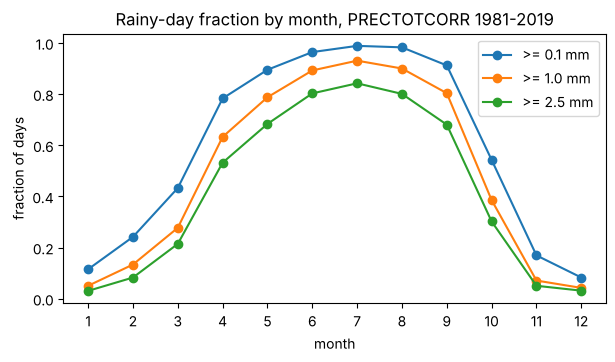

date,1,2,3,4,5,6,7,8,9,10,11,12
>= 0.1 mm,0.11,0.24,0.43,0.78,0.89,0.96,0.99,0.98,0.91,0.54,0.17,0.08
>= 1.0 mm,0.05,0.13,0.28,0.63,0.79,0.89,0.93,0.90,0.80,0.39,0.07,0.04
>= 2.5 mm,0.03,0.08,0.21,0.53,0.68,0.80,0.84,0.80,0.68,0.30,0.05,0.03


In [10]:
wet_frac = pd.DataFrame({f">= {t} mm": (train[TARGET] >= t).groupby(train.index.month).mean() for t in THRESHOLDS})
wet_frac.round(3).to_csv(TAB / "01_wet_day_fraction_by_month_train.csv")
ax = wet_frac.plot(marker="o", figsize=(7, 3.5), title=f"Rainy-day fraction by month, {TARGET} 1981-2019")
ax.set(xlabel="month", ylabel="fraction of days", xticks=range(1, 13)); save(ax.figure, "01_wet_day_fraction_by_month.png")
plt.show()
wet_frac.round(2).T

**Interpretation:** the probability of a ≥ 1 mm day ranges from **4–5 % in Dec–Jan** to **93 % in July**. Jun–Aug is
"almost always wet" and Nov–Feb "almost always dry"; the genuinely uncertain months are **March (28 %), April (63 %),
May (79 %), October (39 %)** and to some extent September (80 %).

**Decision:** (i) the monthly (or day-of-year) climatology baseline will already score well, so ML models must be compared
against it, not against 50 % guessing; (ii) we will also report skill **by season**, because overall scores can look high
simply from easy winter and mid-monsoon days (rule 11).

**Paper note:** *The climatological probability of a rain day (≥ 1 mm) varied from about 4 % in December to 93 % in July,
so that forecast skill is most informative during the pre- and post-monsoon transition months.*

## Section 5 — Persistence of dry and wet weather

### Step 11 — Dry-spell and wet-spell length distributions

**WHAT:** split the training series into runs of consecutive wet days (≥ threshold) and dry days (< threshold) and
summarise their lengths, for each threshold; plot the distribution for the primary 1 mm threshold.

**WHY:** spells measure **persistence**. If wet days tend to follow wet days (long spells), "rain tomorrow = rain today"
(the persistence baseline) will already be strong, and any ML model must beat it. Long dry spells in winter also mean
easy predictions that can inflate overall scores (rule 11).

**Alternatives considered:** a Markov-chain transition matrix P(wet | wet), P(wet | dry) — complementary; we compute it in
the same cell because it is the most direct measure of day-to-day persistence.

**Look for:** median/mean spell lengths, the longest spells, and P(wet tomorrow | wet today) vs P(wet tomorrow | dry today).

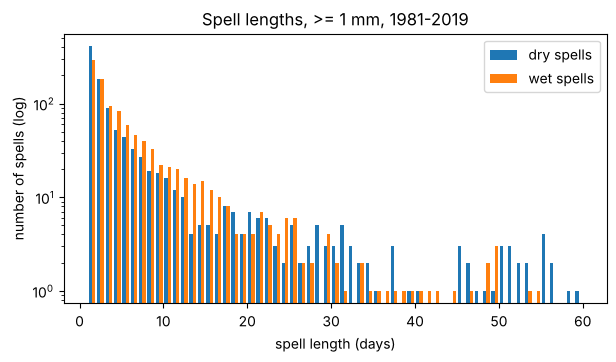

,wet_mean,wet_median,wet_p95,wet_max,dry_mean,dry_median,dry_p95,dry_max,P(wet|wet),P(wet|dry)
>= 0.1 mm,9.61,3.0,44.05,196.0,6.57,3.0,28.0,85.0,0.90,0.15
>= 1.0 mm,6.67,3.0,24.00,138.0,6.84,2.0,31.0,115.0,0.85,0.15
>= 2.5 mm,4.83,3.0,15.70,117.0,6.59,2.0,30.0,120.0,0.79,0.15


In [11]:
def spells(wet):
    run_id = (wet != wet.shift()).cumsum()
    runs = wet.groupby(run_id).agg(["first", "size"])
    return runs.loc[runs["first"], "size"], runs.loc[~runs["first"], "size"]

rows = {}
for t in THRESHOLDS:
    wet = train[TARGET] >= t
    w, d = spells(wet)
    p_ww = (wet & wet.shift(-1, fill_value=False)).sum() / wet.iloc[:-1].sum()
    p_dw = (~wet & wet.shift(-1, fill_value=False)).sum() / (~wet.iloc[:-1]).sum()
    rows[f">= {t} mm"] = {"wet_mean": w.mean(), "wet_median": w.median(), "wet_p95": w.quantile(.95), "wet_max": w.max(),
                          "dry_mean": d.mean(), "dry_median": d.median(), "dry_p95": d.quantile(.95), "dry_max": d.max(),
                          "P(wet|wet)": p_ww, "P(wet|dry)": p_dw}
spell_tab = pd.DataFrame(rows).T
spell_tab.round(2).to_csv(TAB / "01_spell_lengths_train.csv")

w, d = spells(train[TARGET] >= 1.0)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist([d, w], bins=np.arange(1, 61), label=["dry spells", "wet spells"], log=True)
ax.set(xlabel="spell length (days)", ylabel="number of spells (log)", title="Spell lengths, >= 1 mm, 1981-2019")
ax.legend(); save(fig, "01_spell_lengths.png"); plt.show()
spell_tab.round(2)

**Interpretation:**
- **Strong persistence:** P(wet tomorrow | wet today) = **0.85** vs P(wet tomorrow | dry today) = **0.15** at 1 mm.
  The weather "stays as it is" 85 % of the time → the **persistence baseline will be hard to beat** for classification.
- Spells are short in the median (2–3 days) but heavy-tailed: the longest wet spell is **138 days** (a whole monsoon above
  1 mm/day, which is typical of reanalysis drizzle) and the longest dry spell 115 days (winter).
- At 0.1 mm, wet spells are longer (max 196 days): again the model-drizzle effect.

**Decision:** include today's rainfall and short lags as features; report the persistence baseline prominently.
Most "errors" of a persistence model happen at **spell transitions** (onset and end of rain), which is where an ML model
must add value — a useful error-analysis view in Stage 5.

**Paper note:** *Rain occurrence was highly persistent, with a conditional probability of 0.85 for a wet day following a wet
day versus 0.15 following a dry day (≥ 1 mm, 1981–2019).*

## Section 6 — Autocorrelation

### Step 12 — ACF and PACF of rainfall, relative humidity and surface pressure

**WHAT:** autocorrelation (ACF) and partial autocorrelation (PACF) for lags 1–40 days (training period), plus a long ACF
of rainfall up to 800 days.

**WHY:** the **ACF** at lag *k* is the correlation between today and *k* days ago. It tells us how much memory a variable has
and therefore **which lags are worth using as features**. The **PACF** removes the effect of the shorter lags in between,
so it shows which lags add *new* information (if PACF is near zero after lag 2, lags beyond 2 add little).
The long ACF reveals the annual cycle (a peak near lag 365).

**Alternatives considered:** ACF of deseasonalised anomalies — removes the annual cycle and shows short-term memory more
cleanly. We note it as a follow-up; raw ACF is what the models will actually see unless we add anomaly features.

**Look for:** how quickly the ACF decays, the lag where the PACF cuts off, and the annual peak. Shaded bands = 95 %
confidence bands under "no autocorrelation"; with ~14,000 days these bands are very narrow, so *statistical*
significance is easy — focus on *size*.

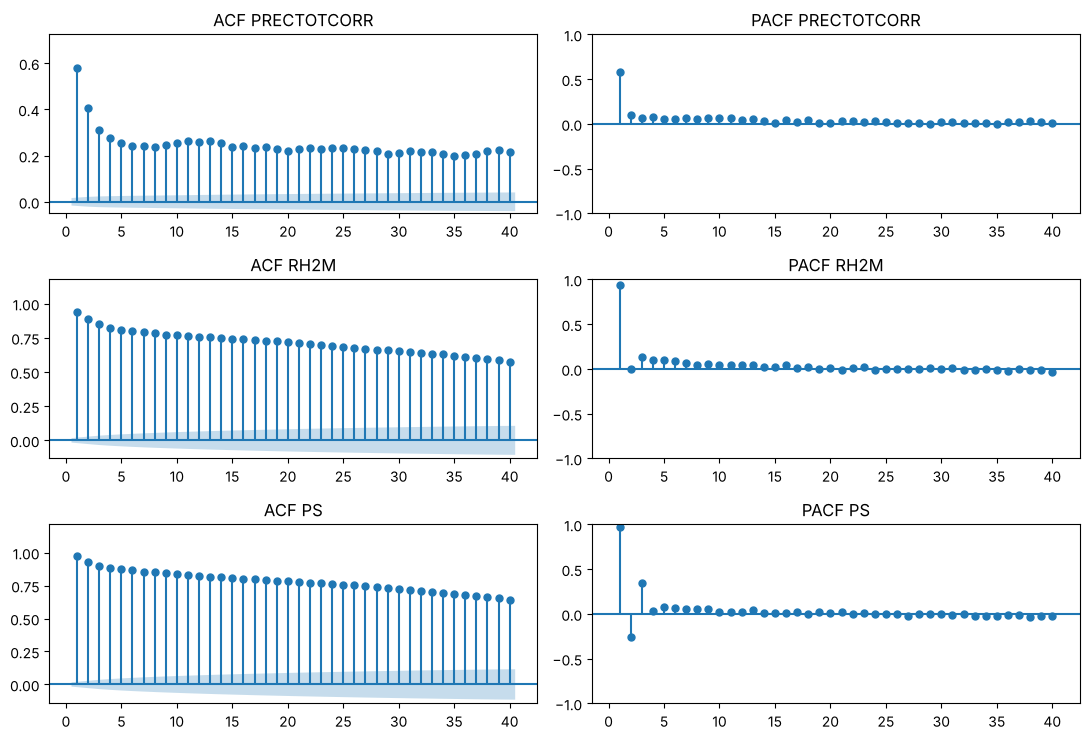

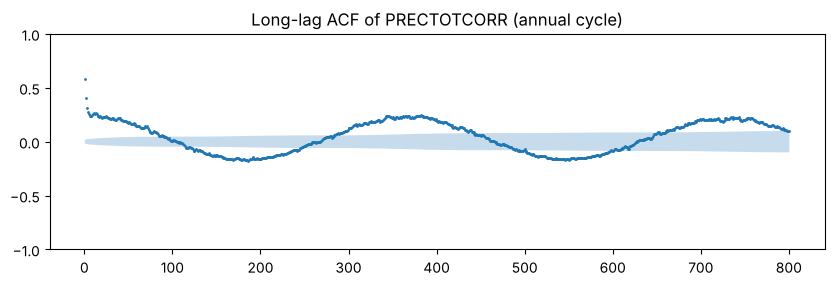

,ACF_PRECTOTCORR,PACF_PRECTOTCORR,ACF_RH2M,PACF_RH2M,ACF_PS,PACF_PS
lag,,,,,,
1,0.58,0.58,0.94,0.94,0.97,0.97
2,0.40,0.10,0.89,-0.00,0.93,-0.25
3,0.31,0.06,0.85,0.14,0.90,0.35
4,0.28,0.08,0.82,0.10,0.89,0.04
5,0.26,0.06,0.81,0.10,0.88,0.08
6,0.24,0.05,0.80,0.09,0.87,0.07
7,0.24,0.06,0.79,0.06,0.86,0.05


In [12]:
ACF_VARS = [TARGET, "RH2M", "PS"]
fig, axes = plt.subplots(len(ACF_VARS), 2, figsize=(11, 7.5))
for i, v in enumerate(ACF_VARS):
    x = train[v].to_numpy()
    plot_acf(x, ax=axes[i, 0], lags=40, zero=False, title=f"ACF {v}", auto_ylims=True)
    plot_pacf(x, ax=axes[i, 1], lags=40, zero=False, method="ywm", title=f"PACF {v}")
fig.tight_layout(); save(fig, "01_acf_pacf.png"); plt.show()

fig, ax = plt.subplots(figsize=(10, 2.8))
plot_acf(train[TARGET].to_numpy(), ax=ax, lags=800, zero=False, use_vlines=False, marker=".", markersize=2,
         title=f"Long-lag ACF of {TARGET} (annual cycle)")
save(fig, "01_acf_long_rain.png"); plt.show()

from statsmodels.tsa.stattools import acf, pacf
acf_tab = pd.DataFrame({f"{k}_{v}": f(train[v].to_numpy(), nlags=7)[1:] for v in ACF_VARS
                        for k, f in (("ACF", acf), ("PACF", pacf))}, index=range(1, 8)).rename_axis("lag")
acf_tab.round(3).to_csv(TAB / "01_acf_pacf_lags1-7.csv")
acf_tab.round(2)

**Interpretation:**
- **Rainfall:** ACF 0.58 at lag 1, 0.40 at lag 2, then it levels off at ~0.22–0.26 and stays there up to lag 40. The PACF is
  0.58 at lag 1, 0.10 at lag 2 and ≤ 0.08 afterwards. So: **lag 1 carries most of the direct information, lag 2 a little**,
  and the long plateau of the ACF is the **seasonal cycle**, not day-to-day memory (the long-lag plot shows the annual
  wave, with peaks near multiples of 365 days).
- **RH2M** and **PS**: very high memory (ACF 0.94 and 0.97 at lag 1, decaying slowly). PACF for RH2M is essentially lag 1
  only; PS has notable PACF at lags 2 (−0.25) and 3 (+0.35) — pressure *tendency* over 2–3 days carries extra information
  (falling pressure ahead of rain systems).

**Decision:** feature set proposal: rainfall lags 1–3 (plus rolling 3-/7-day sums), humidity lag 1, pressure lags 1–3 or
pressure change (PS_t − PS_{t−1}, PS_t − PS_{t−2}). Seasonal features handle the plateau. All lags only use days ≤ t (rule 5).

**Paper note:** *Rainfall autocorrelation decayed rapidly after the first lag (PACF = 0.58 at lag 1, ≤ 0.10 beyond),
whereas humidity and surface pressure showed strong persistence, with partial autocorrelation in pressure up to lag 3.*

## Section 7 — What today tells us about tomorrow

### Step 13 — Spearman correlation of each variable (day *t*) with rainfall on day *t+1*

**WHAT:** pair every variable on day *t* with `PRECTOTCORR` on day *t+1* and compute the Spearman rank correlation, over all
training days and separately by season (season of day *t*).

**WHY:** this respects rule 5 (only information available at the end of day *t*), and it is the first view of which inputs
carry predictive signal. **Spearman** (correlation of ranks) is used instead of Pearson because rainfall is extremely
skewed and the relationships are monotone but not linear; Pearson would be dominated by the few extreme days.

**Why by season?** The overall correlation mixes two things: real day-to-day signal *and* the shared seasonal cycle
(e.g. pressure is low in the monsoon and it rains in the monsoon). Within-season correlations remove most of the
seasonal effect and show the signal a model must actually exploit.

**Alternatives considered:** mutual information (captures non-monotone relations) — useful later for feature screening.
WD2M is excluded (circular variable, invalid after 2012); a sin/cos encoding would be needed.

**Look for:** variables that remain informative *within* seasons, and whether today's rain is the strongest predictor
(persistence).

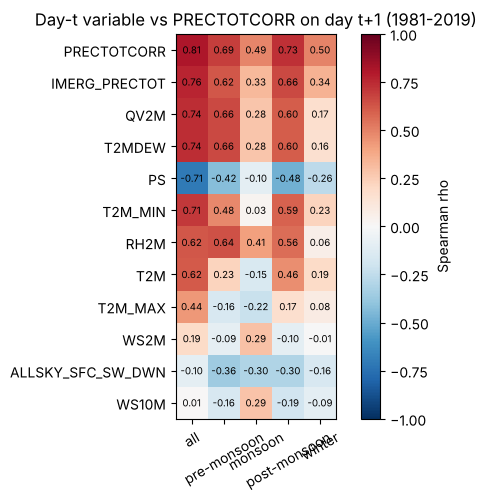

,all,pre-monsoon,monsoon,post-monsoon,winter
PRECTOTCORR,0.81,0.69,0.49,0.73,0.50
IMERG_PRECTOT,0.76,0.62,0.33,0.66,0.34
QV2M,0.74,0.66,0.28,0.60,0.17
T2MDEW,0.74,0.66,0.28,0.60,0.16
PS,-0.71,-0.42,-0.10,-0.48,-0.26
T2M_MIN,0.71,0.48,0.03,0.59,0.23
RH2M,0.62,0.64,0.41,0.56,0.06
T2M,0.62,0.23,-0.15,0.46,0.19
T2M_MAX,0.44,-0.16,-0.22,0.17,0.08
WS2M,0.19,-0.09,0.29,-0.10,-0.01


In [13]:
y_next = df[TARGET].shift(-1).loc[:TRAIN_END]            # rainfall on day t+1 (still inside training years)
X_today = train[[v for v in VARS if v != "WD2M"]]
season = X_today.index.month.map(SEASON)
corr = pd.DataFrame({"all": X_today.corrwith(y_next, method="spearman"),
                     **{s: X_today[season == s].corrwith(y_next[season == s], method="spearman") for s in SEASONS}})
corr = corr.sort_values("all", key=abs, ascending=False)
corr.round(3).to_csv(TAB / "01_spearman_today_vs_rain_tomorrow.csv")

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(corr.shape[1]), corr.columns, rotation=30); ax.set_yticks(range(len(corr)), corr.index)
for (i, j), val in np.ndenumerate(corr.to_numpy()):
    ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="Spearman rho"); ax.set_title(f"Day-t variable vs {TARGET} on day t+1 (1981-2019)")
save(fig, "01_spearman_heatmap.png"); plt.show()
corr.round(2)

**Interpretation:**
- **Overall**, today's rainfall is the strongest predictor of tomorrow's (ρ = 0.81), followed by IMERG today (0.76),
  specific humidity / dew point (0.74), pressure (−0.71) and T2M_MIN (0.71).
- **Within seasons the picture changes a lot** — much of the overall correlation is seasonal:
  - **PS:** −0.71 overall but only −0.10 in the monsoon and −0.26 in winter;
  - **T2M_MIN:** 0.71 overall but 0.03 in the monsoon;
  - **Monsoon** is the hardest season: even persistence is only 0.49, best other inputs are RH2M (0.41) and wind speed (0.29);
  - **Pre- and post-monsoon:** humidity variables (≈ 0.6–0.66) and persistence (≈ 0.7) carry real day-to-day signal;
  - **Radiation** is negative in all seasons (cloudy today → rain tomorrow), ≈ −0.3 in three seasons.
- WS2M/WS10M are near 0 overall but +0.29 in the monsoon: overall correlations can *hide* seasonal signal too.

**Decision:** keep all complete variables as candidate inputs (no feature selection from these numbers — that would
over-fit to training correlations); add season/day-of-year features so models can learn season-specific relationships
(tree models do this automatically; linear models may need interaction terms). Report skill by season.

**Paper note:** *Spearman correlations between day-t predictors and day-(t+1) rainfall were strongly modulated by
season: surface pressure and minimum temperature were highly correlated with next-day rainfall over the full year but
almost uncorrelated within the monsoon season, indicating that much of the annual-scale association reflects the
shared seasonal cycle.*

## Section 8 — Consistency over time (data-source shifts)

### Step 14 — Yearly mean and variance of each variable (full record)

**WHAT:** the annual mean and annual standard deviation of every variable, plotted year by year, with lines at 2016
(suspected shift) and 2020 (test start).

**WHY:** a sudden level or variance change in an otherwise smooth series suggests a change in the input data behind the
product (new satellite, new assimilation stream), not in the climate. If an *input* shifts between training and test,
models learn relationships that no longer hold (**covariate shift**).

**Alternatives considered:** a formal change-point test for every variable — done for rainfall in Step 16; for all other
variables the plot is the screening step.

**Look for:** steps rather than gradual trends, especially in humidity (QV2M, RH2M, T2MDEW) which feed MERRA-2 rainfall.

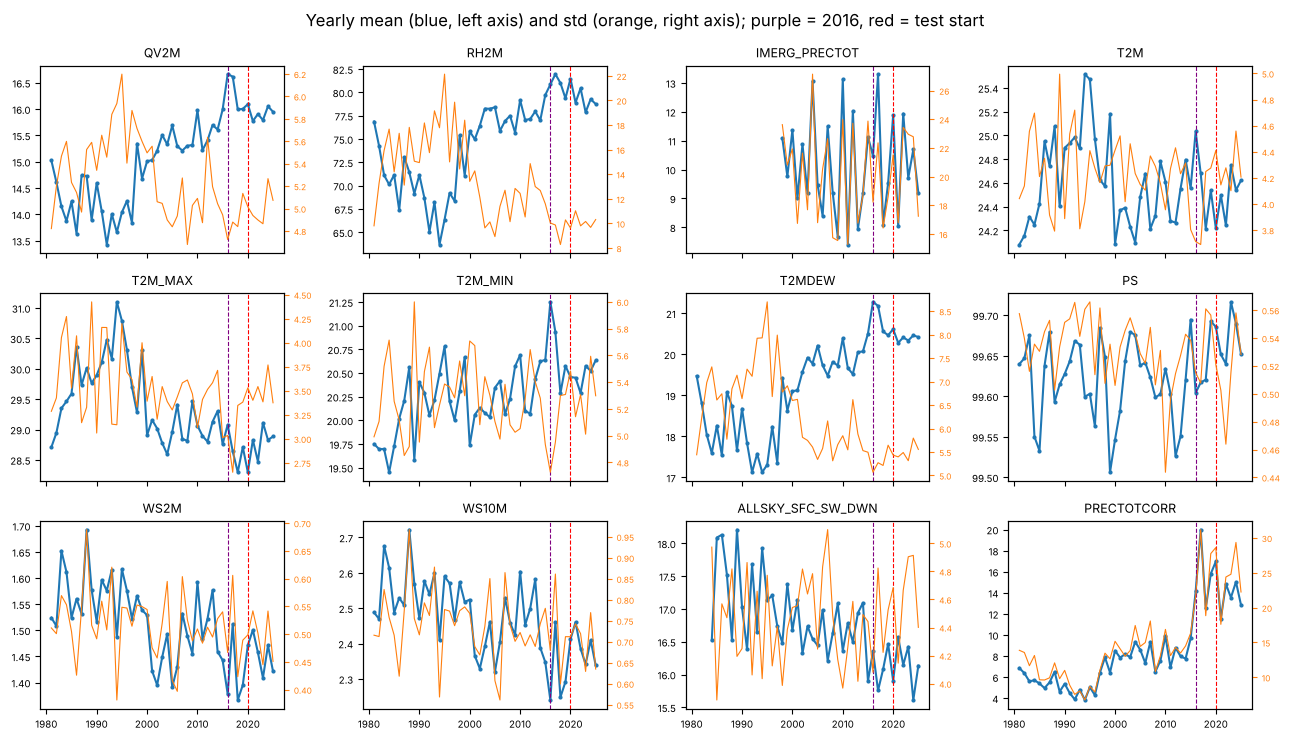

In [14]:
YVARS = [v for v in VARS if v != "WD2M"]
ymean = df[YVARS].groupby(df.index.year).mean()
ystd = df[YVARS].groupby(df.index.year).std()
pd.concat({"mean": ymean, "std": ystd}, axis=1).round(3).to_csv(TAB / "01_yearly_mean_std.csv")

fig, axes = plt.subplots(3, 4, figsize=(13, 7.5), sharex=True)
for ax, v in zip(axes.flat, YVARS):
    ax.plot(ymean.index, ymean[v], "o-", ms=2, label="mean"); ax2 = ax.twinx()
    ax2.plot(ystd.index, ystd[v], color="tab:orange", lw=0.8); ax2.tick_params(labelsize=6, colors="tab:orange")
    for yr, c in ((2016, "purple"), (2020, "red")): ax.axvline(yr, color=c, ls="--", lw=0.8)
    ax.set_title(v, fontsize=9); ax.tick_params(labelsize=7)
fig.suptitle("Yearly mean (blue, left axis) and std (orange, right axis); purple = 2016, red = test start")
fig.tight_layout(); save(fig, "01_yearly_mean_std.png"); plt.show()

**Interpretation:** this figure shows that **the 2016 shift is not limited to rainfall**:
- **Humidity variables (QV2M, RH2M, T2MDEW)** show two steps: a rise around **1998–2000** and another rise in **2016**
  (RH2M: ~64–71 % in the 1990s → ~76–79 % in 2000–2015 → ~80–82 % since 2016; QV2M peaks at 16.7 g/kg in 2016–17), while
  their annual *std* falls — a less variable, moister model climate. T2M_MIN also jumps in 2016.
- **PRECTOTCORR** mirrors this with an even bigger amplitude (annual mean ~4–6 mm/day before 2000 → 8–10 → 12–20 after 2016).
- **T2M, T2M_MAX, PS, wind, radiation**: year-to-year variability, some slow drift (T2M_MAX down slightly), no clear step.
- 1998–2000 is also when satellite inputs to reanalyses changed (e.g. ATOVS microwave sounders were introduced), so a step
  there is plausible as an artefact; we cannot prove the cause from these data alone.

**Decision:** because *inputs* (humidity) also shift, the model faces **covariate shift**, not only target shift. We do not
"correct" inputs (no defensible reference), but the Stage-2 plan includes a training-window ablation and per-period
validation so that the paper can quantify the effect.

**Paper note:** *Annual means of MERRA-2 humidity variables showed step-like increases around 1998–2000 and 2016, parallel
to those in PRECTOTCORR, suggesting that both predictors and target are affected by changes in the reanalysis input data.*

### Step 15 — Trend test on annual rainfall (Mann–Kendall + Sen's slope)

**WHAT:** test for a monotonic trend in annual totals with the **Mann–Kendall** test and estimate its size with **Sen's
slope** (median of all pairwise slopes), for PRECTOTCORR (1981–2025 and 1998–2025) and IMERG (1998–2025).

**WHY:** Mann–Kendall is the standard non-parametric trend test in hydro-climatology: no normality assumption and robust
to outliers. Comparing the two products over the *same* years separates "climate trend" from "product artefact".

**Implementation note (rule 13):** neither scipy nor statsmodels has a function called "Mann–Kendall". The MK statistic
is mathematically Kendall's τ between time and the series, so we use `scipy.stats.kendalltau(year, total)`; Sen's slope is
`scipy.stats.theilslopes`. (The `pymannkendall` package offers variants with autocorrelation correction; annual totals
show little autocorrelation, so the basic test is adequate.)

**Look for:** whether the two products disagree on the existence of a trend over the same period.

In [15]:
def mk_sen(s):
    s = s.dropna(); tau, p = stats.kendalltau(s.index, s.values)
    return {"years": f"{s.index.min()}-{s.index.max()}", "n": len(s), "kendall_tau": tau, "p_value": p,
            "sen_slope_mm_per_yr": stats.theilslopes(s.values, s.index)[0]}

trend = pd.DataFrame({f"{TARGET} full": mk_sen(annual[TARGET]),
                      f"{TARGET} 1998+": mk_sen(annual.loc[1998:, TARGET]),
                      f"{ALT} 1998+": mk_sen(annual[ALT])}).T
trend.to_csv(TAB / "01_trend_tests_annual_rain.csv")
trend

,years,n,kendall_tau,p_value,sen_slope_mm_per_yr
PRECTOTCORR full,1981-2025,45,0.604,0.0,75.081
PRECTOTCORR 1998+,1998-2025,28,0.513,0.0,103.635
IMERG_PRECTOT 1998+,1998-2025,28,-0.016,0.922,-1.647


**Interpretation:**
- PRECTOTCORR has a **strong positive trend** over 1981–2025 (τ = 0.60, p < 10⁻⁸, Sen slope **+75 mm per year**, i.e. about
  +3,300 mm over the record) and still +104 mm/yr within 1998–2025.
- IMERG over the **same years 1998–2025** shows **no trend** (τ = −0.02, p = 0.92, Sen slope −1.6 mm/yr).
- Two products, same place, same years: one says rainfall rose by ~2,800 mm, the other says nothing changed. The
  disagreement itself is the finding — the "trend" in PRECTOTCORR is very likely an artefact.

**Decision:** never interpret the PRECTOTCORR trend as climate change in the paper. Its trend is a property of the dataset.

**Paper note:** *Over 1998–2025, annual PRECTOTCORR totals increased significantly (Mann–Kendall τ = 0.51, p < 0.001;
Sen's slope ≈ 104 mm yr⁻¹), whereas IMERG totals for the same grid cell showed no trend (τ = −0.02, p = 0.92).*

### Step 16 — Regime-shift check: Pettitt change-point test and the 2016 shift

**WHAT:** apply the **Pettitt test** to annual PRECTOTCORR, annual IMERG and their ratio, and compare means and rain-day
frequency before vs after 2016.

**WHY:** a trend test asks "is there a gradual change?"; a change-point test asks "is there a single date where the level
jumps?" — which is what a data-source change looks like. Testing the **ratio** is the sharpest diagnostic: shared weather
variability cancels out, leaving product differences.

**Implementation note (rule 13):** Pettitt is not in scipy or statsmodels, so we implement it in 4 lines following
Pettitt (1979): U_t = Σ_{i≤t} Σ_{j>t} sign(x_i − x_j), K = max|U_t|, approximate p ≈ 2·exp(−6K²/(n³+n²)).
(The `pyhomogeneity` package also provides it; a short transparent function avoids a dependency.)

**Look for:** the change-point year for each series and whether it is significant (p < 0.05).

In [16]:
def pettitt(s):
    s = s.dropna(); x, n = s.to_numpy(), len(s)
    U = np.array([np.sign(x[:t, None] - x[None, t:]).sum() for t in range(1, n)])
    k = np.abs(U).argmax(); K = abs(U[k])
    return {"first_year_after_change": int(s.index[k + 1]), "K": K, "p_value": min(1.0, 2 * np.exp(-6 * K**2 / (n**3 + n**2))),
            "mean_before": x[: k + 1].mean(), "mean_after": x[k + 1:].mean()}

pt = pd.DataFrame({f"{TARGET} 1981-2025": pettitt(annual[TARGET]), f"{TARGET} 1998-2025": pettitt(annual.loc[1998:, TARGET]),
                   f"{ALT} 1998-2025": pettitt(annual[ALT]), "ratio 1998-2025": pettitt(annual["ratio"])}).T
pt.to_csv(TAB / "01_pettitt_tests.csv"); display(pt)

wet_year = (df[[TARGET, ALT]] >= 1).where(df[[TARGET, ALT]].notna()).groupby(df.index.year).mean()
wy = wet_year.loc[1998:]
print("Fraction of days >= 1 mm (mean of yearly values):")
print(wy.groupby(np.where(wy.index < 2016, "1998-2015", "2016-2025")).mean().round(3))

,first_year_after_change,K,p_value,mean_before,mean_after
PRECTOTCORR 1981-2025,2000.0,480.0,7.175e-07,1996.952,3923.828
PRECTOTCORR 1998-2025,2015.0,185.0,2.391e-04,2937.468,5209.210
IMERG_PRECTOT 1998-2025,2015.0,29.0,1.000e+00,3657.635,3784.965
ratio 1998-2025,2016.0,180.0,3.870e-04,0.819,1.436


Fraction of days >= 1 mm (mean of yearly values):
           PRECTOTCORR IMERG_PRECTOT
1998-2015        0.505         0.475
2016-2025        0.570         0.475


**Interpretation:**
- **PRECTOTCORR 1981–2025:** most significant change point **2000** (p ≈ 7 × 10⁻⁷; mean 1,997 → 3,924 mm). Pettitt detects
  only the single strongest break; on the 1998–2025 subset it finds a second one at **2015/2016** (p ≈ 2 × 10⁻⁴;
  2,937 → 5,209 mm). So PRECTOTCORR has **two** regime shifts: ~2000 and ~2016.
- **IMERG 1998–2025:** no change point (p = 1.0; 3,658 vs 3,785 mm).
- **Ratio:** change point exactly at **2016** (p ≈ 4 × 10⁻⁴; 0.82 → 1.44).
- **Rain-day frequency (≥ 1 mm):** PRECTOTCORR 50.5 % → 57.0 % after 2016; IMERG unchanged (47.5 % → 47.5 %). So the shift
  also changes the **classification** base rate, not just amounts — this confirms your answer to Question 1.

**Decision:** document both breaks (2000, 2016) in the paper. They justify the IMERG robustness analysis and a
training-window ablation, and they affect the validation design (2014–2019 straddles the 2016 break).

**Paper note:** *Pettitt tests identified significant change points in annual PRECTOTCORR around 2000 (p < 0.001) and
2016 (p < 0.001), and in the PRECTOTCORR/IMERG ratio in 2016 (p < 0.001), while no change point was detected in IMERG
(p = 1.0).*

### Step 17 — Last 12 months vs earlier years

**WHAT:** for each variable, compare each month of the last 12 months in the record (Jan–Dec 2025) with the same calendar
month in 1981–2024, expressed as a **z-score** = (2025 monthly mean − historical mean) / historical std.

**WHY:** recent data are the most likely to come from a different processing stream (e.g. near-real-time vs final
reanalysis products, or a new IMERG version) — the "last 12 months" check catches such late changes. Using same-month
comparisons removes the seasonal cycle. This is an integrity check only; no model decision is taken from it.

**Alternatives considered:** a two-sample KS test per variable — gives p-values but no direction or month; z-scores by
month are easier to interpret.

**Look for:** |z| > 3 (very unusual), and whether unusual values cluster in one variable (suggesting a data issue) or
spread across physically linked variables (suggesting real weather).

In [17]:
last = df.loc["2025", YVARS].groupby(df.loc["2025"].index.month).mean()
hist = df.loc[:"2024", YVARS].groupby(df.loc[:"2024"].index.year * 100 + df.loc[:"2024"].index.month).mean()
hist_m = hist.groupby(hist.index % 100)
z = ((last - hist_m.mean()) / hist_m.std()).round(2)
z.to_csv(TAB / "01_last12months_zscores.csv")
print("months with |z| > 3:", {v: z.index[z[v].abs() > 3].tolist() for v in YVARS if (z[v].abs() > 3).any()})
print("max |z| per variable:\n", z.abs().max().round(2).sort_values(ascending=False).to_string())
z.style.background_gradient(cmap="RdBu_r", vmin=-3, vmax=3).format("{:.1f}")

months with |z| > 3: {'PRECTOTCORR': [5]}
max |z| per variable:
 PRECTOTCORR          3.23
PS                   2.22
IMERG_PRECTOT        2.13
T2M                  1.76
T2M_MIN              1.66
QV2M                 1.57
T2MDEW               1.54
WS2M                 1.42
WS10M                1.27
T2M_MAX              1.27
ALLSKY_SFC_SW_DWN    1.21
RH2M                 1.02


,QV2M,RH2M,IMERG_PRECTOT,T2M,T2M_MAX,T2M_MIN,T2MDEW,PS,WS2M,WS10M,ALLSKY_SFC_SW_DWN,PRECTOTCORR
date,,,,,,,,,,,,
1,1.3,1.0,-0.7,0.7,-0.3,1.3,1.2,-0.1,-0.7,-1.1,-1.0,-0.7
2,0.7,0.8,-0.7,-0.4,-0.8,-0.0,0.7,0.8,-1.1,-0.9,-0.8,-0.8
3,0.7,0.7,-0.8,-0.5,-0.7,-0.0,0.7,0.3,-0.2,-0.2,-0.7,-0.5
4,0.7,0.7,-0.2,-0.6,-0.8,0.2,0.7,1.1,-0.8,-0.7,-1.2,0.9
5,1.1,0.8,2.1,-0.3,-0.8,0.8,1.0,-0.1,0.6,0.8,-1.2,3.2
6,1.0,0.4,-1.4,0.3,-0.1,0.9,1.0,0.3,-1.2,-1.1,0.8,-0.1
7,0.8,-0.2,-0.7,1.2,0.8,0.9,0.8,-0.9,-1.3,-1.2,-0.1,0.5
8,0.3,1.0,0.4,-1.0,-1.1,-0.2,0.4,2.2,0.6,0.6,-0.8,1.6
9,1.6,0.4,0.0,1.3,0.8,1.7,1.5,-0.5,-0.7,-0.6,0.2,0.7


**Interpretation:** only one month in 2025 is unusual: **PRECTOTCORR in May 2025, z = 3.2**. IMERG for the same month is
within normal range (max |z| over 2025 = 2.1), and every other variable has |z| ≤ 2.2. Since the historical reference
(1981–2024) is dominated by the *low* PRECTOTCORR regime, a high z for PRECTOTCORR in 2025 is expected from the 2016 shift
itself; relative to the post-2016 years it would be unremarkable. There is **no sign of a new data-source change in the
last 12 months** (e.g. a switch to near-real-time processing).

**Decision:** no new issue; the 2025 data are consistent with the 2016–2024 regime.

**Paper note:** *The most recent 12 months of data showed no anomalies beyond those expected from the documented 2016
discontinuity in PRECTOTCORR, indicating no further change in data provenance at the end of the record.*

## Section 9 — Problems found and proposed Stage-2 cleaning plan (awaiting your approval)

### Problems found
| # | Problem | Evidence | Severity |
|---|---|---|---|
| P1 | **WD2M invalid** from 2012-12-31 to 2025-12-31 (−8,998 … −5,401) | Steps 3–4 | High — unusable in validation and test |
| P2 | **PRECTOTCORR (primary target) has two regime shifts**, ~2000 and 2016; artificial upward trend (+75 mm/yr) | Steps 8, 15, 16 | **Critical** — training mixes regimes; test is entirely in the newest regime |
| P3 | **Humidity inputs (QV2M, RH2M, T2MDEW, T2M_MIN) shift in parallel** (~1998–2000, 2016) | Step 14 | High — covariate shift between training and test |
| P4 | Post-2015 PRECTOTCORR extremes often not confirmed by IMERG (288 vs 41 mm) | Step 7 | Medium — dominates RMSE |
| P5 | `ALLSKY_SFC_SW_DWN` missing 1981–1983; `IMERG_PRECTOT` missing 1981–1997 | Step 3 | Medium — limits feature sets/periods |
| P6 | PRECTOTCORR trace-amount "drizzle" (many 0.01–0.09 mm values; 138-day wet spells at 1 mm) | Steps 5, 11 | Low — handled by ≥ 1 mm threshold |
| P7 | Header labels IMERG_PRECTOT as "MERRA-2" | Stage 0 | Low — documentation |

### Proposed cleaning / preparation plan for Stage 2 (nothing done yet)
1. **WD2M:** drop from all feature sets (your decision). *Optional:* re-download `U2M`/`V2M` (or `U10M`/`V10M`) from POWER to
   recover a valid wind-direction signal as sin/cos components.
2. **Target construction:** `y_reg(t) = PRECTOTCORR(t+1)`; `y_cls(t) = PRECTOTCORR(t+1) ≥ 1 mm` (and 0.1 / 2.5 mm); drop the last
   day (no t+1). Same for `IMERG_PRECTOT` (1998–2025) as secondary target. **No correction, capping or removal of target
   values** (P2, P4) — documented, not fixed.
3. **Feature Set A (complete 1981–2025):** QV2M, RH2M, T2M, T2M_MAX, T2M_MIN, T2MDEW, PS, WS2M, WS10M, PRECTOTCORR (today)
   + lags/rolling features from Step 12 + day-of-year sin/cos.
   **Feature Set B (extended):** A + ALLSKY_SFC_SW_DWN (→ training starts 1984-01-01) — no imputation of 1981–1983.
   IMERG_PRECTOT as an *input* only in the 1998+ IMERG experiments.
4. **No imputation needed** for Feature Set A (complete); scaling only inside Pipelines (rule 6).
5. **Splits:** train 1981–2019, validation folds within 2014–2019 (expanding window), test 2020–2025 locked.
   Because of P2/P3, **report validation separately for 2014–2015 and 2016–2019**.
6. **Robustness (Stage 6):** IMERG target 1998–2025; training-window ablation (start 1981 / 2000 / 2016); per-season scores.

**Please approve, modify or reject items 1–6 before Stage 2.**